# 02 — cGAN Experiments on Fashion-MNIST

Group **A Day in Ali** · CAK4KBB3 Project 1

This notebook runs and inspects the conditional GAN. All reusable logic lives in
`src/`; the notebook only calls it and shows the results:

1. Setup and data check
2. Model size
3. Training (resumes from the latest checkpoint if one exists)
4. Loss curves
5. Fixed-grid progress across epochs
6. Fresh samples per class from the trained generator
7. Observations

## 1. Setup

In [1]:
import os
import sys
from pathlib import Path

# Run from the repo root so `src` imports and relative paths work.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision.utils import make_grid

from src.config import CHECKPOINTS_DIR, CLASS_NAMES, LATENT_DIM, LOGS_DIR, NUM_CLASSES, SAMPLES_DIR, SEED
from src.data import get_dataloader
from src.models import Discriminator, Generator, count_parameters
from src.plots import save_loss_curves
from src.train import train
from src.utils import get_device, load_checkpoint, set_seed

%matplotlib inline
print("Repo root:", ROOT)
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

Repo root: E:\Gen AI
torch 2.14.1+cpu | CUDA available: False


### Experiment settings

Change these before running. `EPOCHS` is the last epoch to reach: with `RESUME = True`
an existing `outputs/checkpoints/ckpt.pt` is continued instead of starting over, so
re-running the notebook after training finishes does not retrain.

One epoch at batch size 128 takes about 80 seconds on a laptop CPU (≈40 minutes for 30).
Set `MAX_BATCHES` to a small number (e.g. `20`) for a quick smoke run.

In [2]:
EPOCHS = 30
BATCH_SIZE = 128
LR = 2e-4
SAMPLE_EVERY = 5
RESUME = True
MAX_BATCHES = None  # e.g. 20 for a quick smoke run
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

set_seed(SEED)
device = get_device(DEVICE)
print("Device:", device)

Device: cpu


### Data check

One batch of real images, rescaled from `[-1, 1]` back to `[0, 1]` for display.

Batch: (128, 1, 28, 28) | range: -1.0 to 1.0
Labels in batch: ['Ankle boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt/top', 'Trouser']


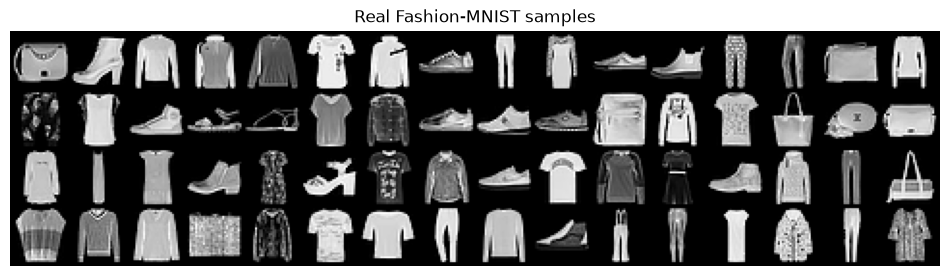

In [3]:
loader = get_dataloader(batch_size=BATCH_SIZE, seed=SEED)
images, labels = next(iter(loader))
print("Batch:", tuple(images.shape), "| range:", round(images.min().item(), 3), "to", round(images.max().item(), 3))
print("Labels in batch:", sorted({CLASS_NAMES[i] for i in labels.tolist()}))

grid = make_grid(images[:64], nrow=16, normalize=True, value_range=(-1, 1))
plt.figure(figsize=(12, 3.5))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Real Fashion-MNIST samples")
plt.show()

## 2. Model size

In [4]:
g_params = count_parameters(Generator())
d_params = count_parameters(Discriminator())
print(f"Generator:     {g_params:>9,}")
print(f"Discriminator: {d_params:>9,}")
print(f"Total:         {g_params + d_params:>9,}")

Generator:       741,249
Discriminator:   192,881
Total:           934,130


## 3. Training

Each batch runs one discriminator update and one generator update
(`BCEWithLogitsLoss`, real targets 0.9, fake targets 0.0). Checkpoints, sample grids,
`history.json`, and `loss_curves.png` are written under `outputs/`.

In [5]:
ckpt_path = CHECKPOINTS_DIR / "ckpt.pt"
resume_from = ckpt_path if RESUME and ckpt_path.exists() else None
print("Resuming from:" if resume_from else "Starting fresh.", resume_from or "")

history = train(
    loader,
    epochs=EPOCHS,
    lr=LR,
    device=device,
    sample_every=SAMPLE_EVERY,
    resume=resume_from,
    seed=SEED,
    max_batches=MAX_BATCHES,
    progress=False,  # one summary line per epoch keeps the notebook small
)
print("Epochs recorded:", len(history["loss_d"]))

Starting fresh. 


Epoch 1/30  loss_d=0.8210  loss_g=1.7735  acc_d=0.900  D(x)=0.658  D(G(z))=0.241


Epoch 2/30  loss_d=0.7424  loss_g=2.0493  acc_d=0.911  D(x)=0.695  D(G(z))=0.201


Epoch 3/30  loss_d=0.8224  loss_g=1.8360  acc_d=0.881  D(x)=0.664  D(G(z))=0.234


Epoch 4/30  loss_d=0.8620  loss_g=1.6956  acc_d=0.870  D(x)=0.646  D(G(z))=0.253


...

Epoch 27/30  loss_d=0.6642  loss_g=2.4426  acc_d=0.926  D(x)=0.739  D(G(z))=0.160


Epoch 28/30  loss_d=0.6579  loss_g=2.4728  acc_d=0.929  D(x)=0.742  D(G(z))=0.157


Epoch 29/30  loss_d=0.6589  loss_g=2.4931  acc_d=0.928  D(x)=0.742  D(G(z))=0.157


Epoch 30/30  loss_d=0.6526  loss_g=2.5113  acc_d=0.929  D(x)=0.746  D(G(z))=0.154


Epochs recorded: 30


## 4. Loss curves

Healthy cGAN training usually shows both losses settling into a band rather than one
going to zero. Warning signs: discriminator loss near 0 with accuracy near 1
(D wins, G stops learning), or `D(G(z))` stuck near 0.

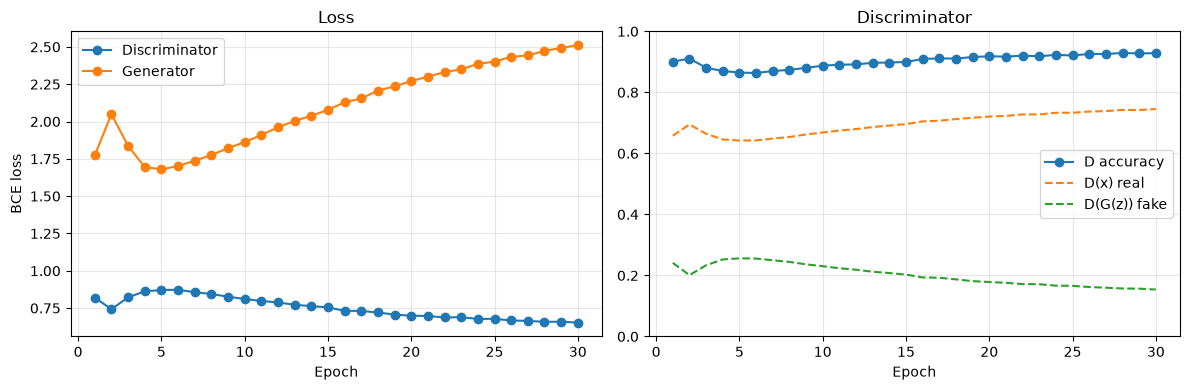

epoch   loss_d   loss_g  acc_d   D(x)  D(G(z))
    1   0.8210   1.7735  0.900  0.658    0.241
    2   0.7424   2.0493  0.911  0.695    0.201
    3   0.8224   1.8360  0.881  0.664    0.234
    4   0.8620   1.6956  0.870  0.646    0.253
    5   0.8712   1.6792  0.865  0.642    0.256
    6   0.8730   1.7022  0.864  0.642    0.255
    7   0.8565   1.7370  0.870  0.649    0.250
    8   0.8444   1.7759  0.874  0.654    0.244
    9   0.8263   1.8212  0.880  0.662    0.236
   10   0.8110   1.8622  0.888  0.668    0.230
   11   0.7976   1.9100  0.890  0.675    0.224
   12   0.7882   1.9613  0.892  0.680    0.219
   13   0.7720   2.0039  0.897  0.686    0.212
   14   0.7633   2.0386  0.898  0.691    0.208
   15   0.7548   2.0786  0.900  0.696    0.203
   16   0.7317   2.1286  0.909  0.705    0.194
   17   0.7309   2.1544  0.911  0.707    0.192
   18   0.7206   2.2076  0.911  0.713    0.187
   19   0.7062   2.2354  0.916  0.717    0.181
   20   0.6992   2.2717  0.918  0.721    0.179
   21   0.697

In [6]:
epochs_axis = range(1, len(history["loss_d"]) + 1)
fig, (ax_loss, ax_d) = plt.subplots(1, 2, figsize=(12, 4))
ax_loss.plot(epochs_axis, history["loss_d"], marker="o", label="Discriminator")
ax_loss.plot(epochs_axis, history["loss_g"], marker="o", label="Generator")
ax_loss.set(xlabel="Epoch", ylabel="BCE loss", title="Loss")
ax_loss.legend()
ax_d.plot(epochs_axis, history["acc_d"], marker="o", label="D accuracy")
ax_d.plot(epochs_axis, history["d_real"], linestyle="--", label="D(x) real")
ax_d.plot(epochs_axis, history["d_fake"], linestyle="--", label="D(G(z)) fake")
ax_d.set(xlabel="Epoch", ylim=(0, 1), title="Discriminator")
ax_d.legend()
for ax in (ax_loss, ax_d):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'epoch':>5} {'loss_d':>8} {'loss_g':>8} {'acc_d':>6} {'D(x)':>6} {'D(G(z))':>8}")
for i in epochs_axis:
    j = i - 1
    print(f"{i:>5} {history['loss_d'][j]:>8.4f} {history['loss_g'][j]:>8.4f} "
          f"{history['acc_d'][j]:>6.3f} {history['d_real'][j]:>6.3f} {history['d_fake'][j]:>8.3f}")

## 5. Fixed-grid progress

Every saved grid uses the same noise and labels, so changes between epochs come only
from training. Rows are classes in order (T-shirt/top at the top, Ankle boot at the bottom).

Saved grids: ['epoch_001.png', 'epoch_005.png', 'epoch_010.png', 'epoch_015.png', 'epoch_020.png', 'epoch_025.png', 'epoch_030.png']


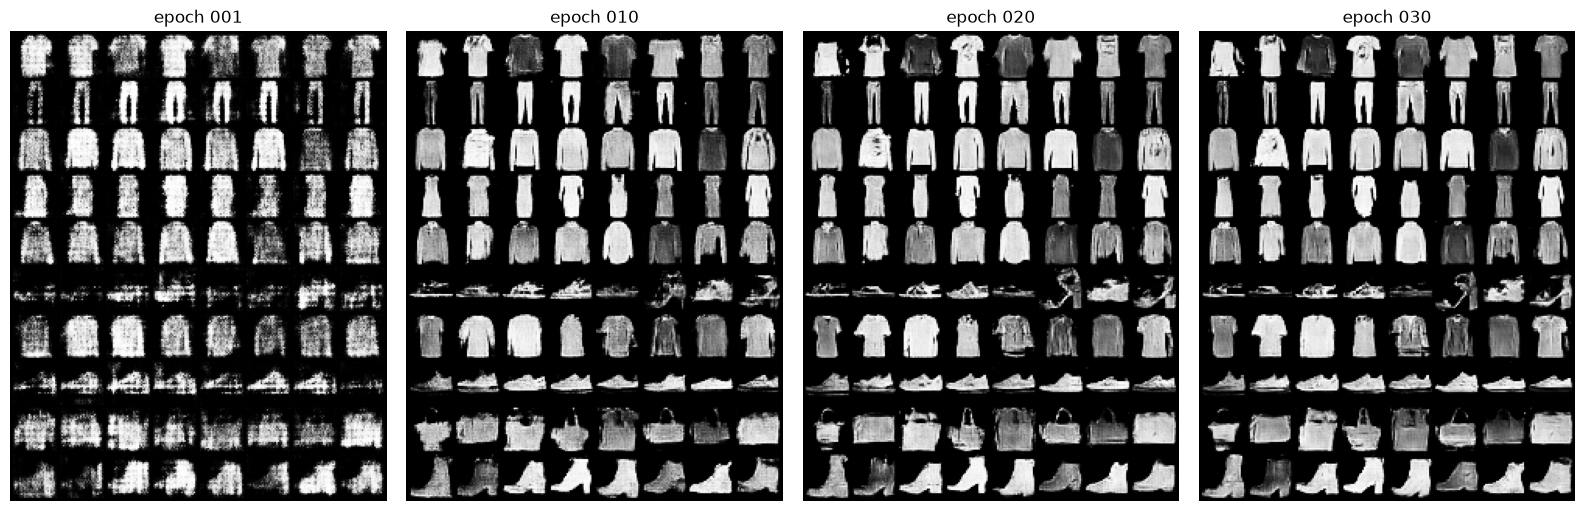

In [7]:
grid_files = sorted(SAMPLES_DIR.glob("epoch_*.png"))
print("Saved grids:", [p.name for p in grid_files])

if grid_files:
    # Show at most 4 grids, evenly spaced from first to last.
    n = len(grid_files)
    show = [grid_files[i] for i in sorted({round(k * (n - 1) / 3) for k in range(4)})]
    fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 5), squeeze=False)
    for ax, path in zip(axes[0], show):
        ax.imshow(Image.open(path), cmap="gray")
        ax.set_title(path.stem.replace("_", " "))
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 6. Fresh samples per class

New random noise (not the fixed grid) through the latest generator, in eval mode.
Each row should clearly show its labelled class and still vary within the row;
identical images across a row would suggest mode collapse.

Loaded generator from epoch 30


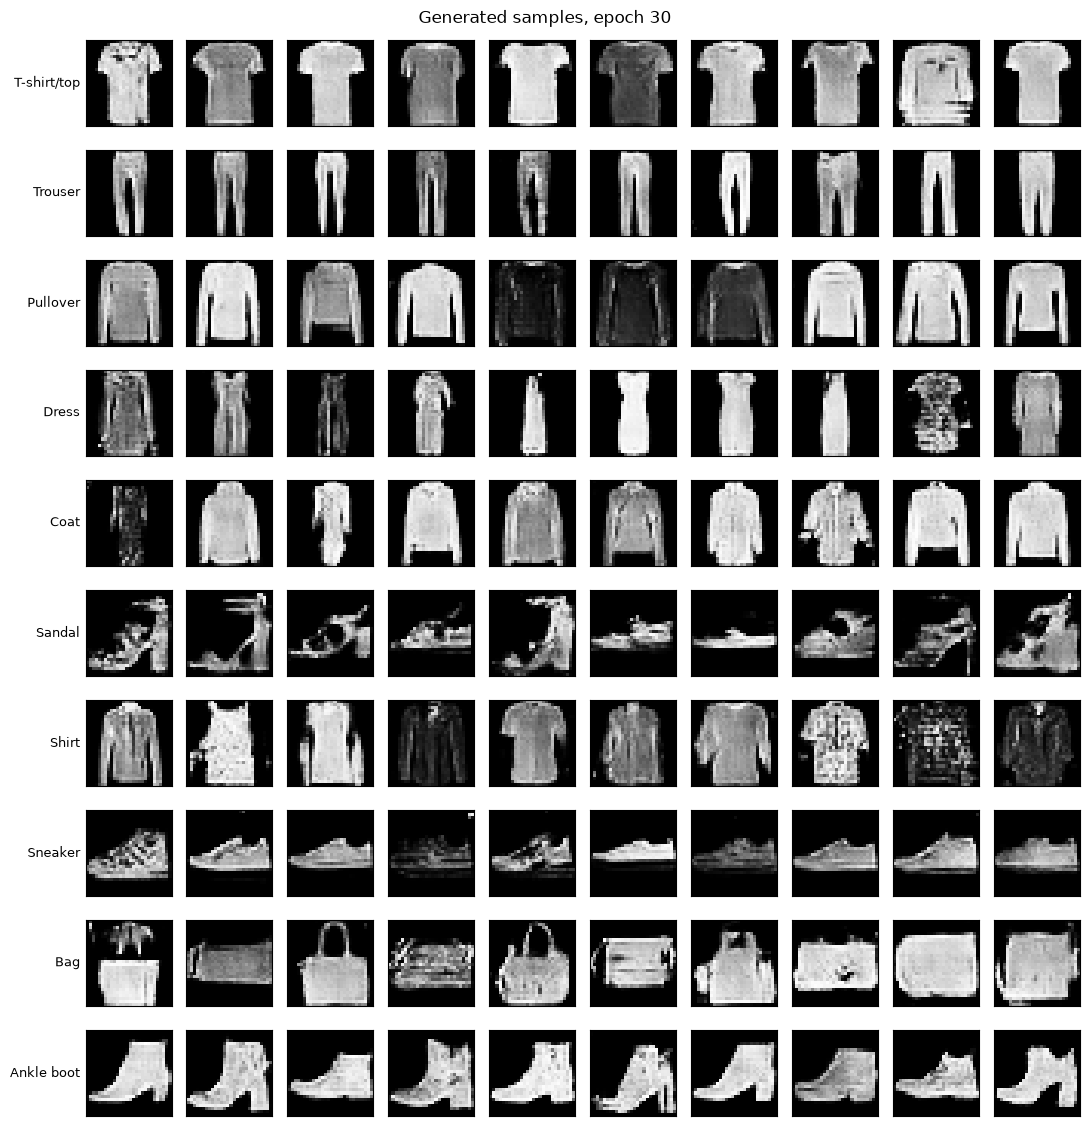

In [8]:
generator = Generator().to(device)
ckpt = load_checkpoint(ckpt_path, generator, device=device)
generator.eval()
print("Loaded generator from epoch", ckpt["epoch"])

per_class = 10
gen_rng = torch.Generator().manual_seed(SEED + 1)
z = torch.randn(NUM_CLASSES * per_class, LATENT_DIM, generator=gen_rng).to(device)
y = torch.arange(NUM_CLASSES, device=device).repeat_interleave(per_class)
with torch.no_grad():
    fakes = generator(z, y).cpu()

fig, axes = plt.subplots(NUM_CLASSES, per_class, figsize=(per_class * 1.1, NUM_CLASSES * 1.15))
for row in range(NUM_CLASSES):
    for col in range(per_class):
        ax = axes[row, col]
        ax.imshow(fakes[row * per_class + col, 0], cmap="gray", vmin=-1, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(CLASS_NAMES[row], rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle(f"Generated samples, epoch {ckpt['epoch']}")
plt.tight_layout()
plt.show()

## 7. Observations

Baseline run: 30 epochs, batch size 128, lr 2e-4, CPU (~80 s/epoch, ~40 min total).
These notes feed the *Optimasi* section of `logs/LOG_INTERAKSI_LLM.md` and the final report.

- **Training stability:** no divergence or collapse. After a short dip (epochs 3–6) the
  discriminator slowly gains ground: D accuracy rises from 0.86 to 0.93, `D(G(z))` falls
  from 0.26 to 0.15, and generator loss climbs from 1.68 to 2.51. Visual quality still
  improves up to epoch 30, but the gain from epoch 20 to 30 is small, so training much
  longer with this setup is unlikely to help.
- **Class quality:** Trouser, Sneaker, Ankle boot, T-shirt/top, and Pullover are clean and
  clearly conditioned on the label. Sandal and Bag are recognisable but noisier. Shirt and
  Coat are the weakest: some Shirt samples look like T-shirts or have noisy textures, and
  one Coat sample is a thin dress-like shape. These classes overlap visually in the dataset.
- **Diversity / mode collapse:** none visible. Rows vary in shade, pattern, and shape
  (heeled vs. flat sandals, tote vs. clutch bags, light vs. dark pullovers).
- **Next experiment (max two variants):** because D slowly overpowers G, try
  (1) removing BatchNorm from the discriminator's first conv layer, or
  (2) a lower discriminator learning rate (e.g. 1e-4). Compare both against this baseline
  with conditional accuracy once `src/evaluate.py` exists.